# Transmitir una trama LoRa y detectar su inicio

Una sola captura del Pluto. El cuaderno arma la trama, configura/transmite/recibe/cierra el SDR en **una celda**, detecta por correlación temporal de la cabecera y muestra lo observado. Las muestras quedan en memoria; no se guardan archivos. La celda del SDR se ejecuta solo cuando el equipo está conectado.

## 1. Armado de la trama

Se transmite un símbolo de silencio seguido de 8 upchirps, 2¼ downchirps y los diez bytes de `hola mundo`. Cada chirp y cada símbolo de datos tienen potencia media 1. El silencio marca la separación entre repeticiones del buffer cíclico.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import correlate, find_peaks

SF = 8
FS = BW = 2_000_000
N = 2**SF
k = np.arange(N)
mensaje = b'hola mundo'

def modular_simbolo(valor):
    fase = ((valor + k) % N) * k / N
    return np.exp(2j * np.pi * fase)

upchirp = np.exp(2j * np.pi * k**2 / N)
downchirp = np.conj(upchirp)
cabecera = np.concatenate([np.tile(upchirp, 8), downchirp, downchirp,
                           downchirp[:N // 4]])
payload = np.concatenate([modular_simbolo(byte) for byte in mensaje])
trama = np.concatenate([cabecera, payload])
tx_signal = np.concatenate([np.zeros(N), trama])

# Comprobación local del mensaje armado, antes de usar el SDR.
espectros_tx = np.fft.fft(payload.reshape(-1, N) * np.conj(upchirp), axis=1)
bytes_tx = bytes(np.argmax(np.abs(espectros_tx), axis=1).tolist())
assert bytes_tx == mensaje
print(f'TX: {N} silencio + {len(cabecera)} cabecera + {len(payload)} payload '
      f'= {len(tx_signal)} muestras por período')
print('Bytes TX comprobados:', bytes_tx)

TX: 256 silencio + 2624 cabecera + 2560 payload = 5440 muestras por período
Bytes TX comprobados: b'hola mundo'


## 2. Configuración, envío, recepción y limpieza

Esta es la **única celda que toca el SDR**. Hace una captura RX de cuatro períodos esperados y deja `rx_signal` en memoria. El bloque `finally` apaga la transmisión, destruye los buffers y elimina el objeto SDR incluso si aparece un error.

In [ ]:
import adi

rx_signal = None  # Evita analizar una captura anterior si esta ejecución falla.
sdr = adi.Pluto('ip:192.168.1.34')
try:
    sdr.tx_destroy_buffer()
    sdr.rx_destroy_buffer()
    sdr.loopback = 0
    sdr.sample_rate = FS
    sdr.tx_lo = 915_000_000
    sdr.rx_lo = 915_000_000
    sdr.tx_rf_bandwidth = BW
    sdr.rx_rf_bandwidth = BW
    sdr.tx_hardwaregain_chan0 = -50
    sdr.gain_control_mode_chan0 = 'slow_attack'
    sdr.rx_buffer_size = 4 * len(tx_signal)
    sdr.tx_cyclic_buffer = True

    # =======================================================================
    # sdr.tx() ENTREGA 4 SEÑAL
    #
    # 5440 muestras IQ: silencio + cabecera + payload.
    # Cada muestra ocupa 4 bytes (I y Q de 16 bits). 
    # En la versión instalada de pyadi/libiio v1, 
    # sdr.tx() creó un bloque cíclico de 5440 BYTES cuando recibió 5440 MUESTRAS.
    # Así el equipo repitió solo 5440/4 = 1360 muestras:
    # el silencio y el comienzo de los upchirps, pero NO los downchirps ni
    # el payload. El lector de bytes veía entonces datos que nunca salieron.
    #
    # Lo detectamos midiendo el periodo de tx que encontramos en |RX|
    # Al pasar cuatro copias se usa el primer cuarto: una trama lógica completa.
    # Si la biblioteca se corrige, transmitirá cuatro tramas idénticas
    # =======================================================================
    tx_para_sdr = np.tile(tx_signal, 4)
    sdr.tx(tx_para_sdr * (2**15 - 1))
    print(f'Envío: {len(tx_para_sdr)} muestras entregadas a sdr.tx; '
          f'período lógico {len(tx_signal)}')

    rx_signal = np.asarray(sdr.rx()).copy()
    print(f'Recepción: {len(rx_signal)} muestras; esperadas {sdr.rx_buffer_size}')
    if len(rx_signal) != sdr.rx_buffer_size:
        rx_signal = None
        raise RuntimeError('RX incompleta')
finally:
    # No se envía otro bloque de ceros: en esta ruta provocó fallas del kernel.
    try:
        sdr.tx_hardwaregain_chan0 = -89
        sdr.tx_lo = int(2400e6)
    finally:
        try:
            sdr.tx_destroy_buffer()
        finally:
            try:
                sdr.rx_destroy_buffer()
                # poner que mande 0s
            finally:
                del sdr
                print('SDR cerrado: buffers liberados y objeto eliminado.')

Envío: 21760 muestras entregadas a sdr.tx; período lógico 5440
Recepción: 21760 muestras; esperadas 21760
SDR cerrado: buffers liberados y objeto eliminado.


## 3. Detección y lectura

Primero se comprueba que la repetición RX mida **5440 muestras**; si mide alrededor de **1360**, el TX quedó truncado y no tiene sentido interpretar bytes. Luego se desliza la cabecera completa sobre RX: la curva `|correlación|²` normalizada da un puntaje entre 0 y 1 para cada posible inicio. Se elige el máximo, se acepta desde **0,20** y recién ahí se demodulan los diez bytes. La corrección de frecuencia del lector solo se usa para los bytes; no interviene en la detección del inicio.

In [ ]:
def correlacion_normalizada(iq, referencia):
    numerador = np.abs(correlate(iq, referencia, mode='valid', method='fft'))
    energia = np.r_[0.0, np.cumsum(np.abs(iq)**2)]
    energia_ventana = energia[len(referencia):] - energia[:-len(referencia)]
    puntaje = np.zeros(len(numerador))
    hay_senal = energia_ventana > 16 * np.finfo(float).eps * energia[-1]
    puntaje[hay_senal] = numerador[hay_senal] / np.sqrt(
        energia_ventana[hay_senal] * np.sum(np.abs(referencia)**2))
    return np.clip(puntaje, 0, 1)


def leer_payload(iq, inicio):
    # Los upchirps estiman el giro de fase por muestra para corregir el payload. --------- INVESTIGAR WTF ESE OFFSET
    pre = iq[inicio:inicio+8*N].reshape(8, N) * np.conj(upchirp)
    fase = np.sum(pre[:, 1:] * np.conj(pre[:, :-1]))
    offset = np.angle(fase) / (2*np.pi)
    comienzo = inicio + len(cabecera)
    datos = iq[comienzo:comienzo+len(payload)]
    indices = len(cabecera) + np.arange(len(datos))
    corregidos = datos * np.exp(-2j*np.pi*offset*indices)
    espectros = np.abs(np.fft.fft(
        corregidos.reshape(len(mensaje), N) * np.conj(upchirp), axis=1))
    return bytes(np.argmax(espectros, axis=1).tolist()), espectros, offset * FS


if rx_signal is None:
    raise RuntimeError('Ejecutá primero la celda SDR; no hay captura válida')

# El período verifica que TX repetía la trama completa antes de leer bytes. -------- VER QUE VRGA ES ESTO
envolvente = np.abs(rx_signal)
autocorr = correlate(envolvente - envolvente.mean(),
                     envolvente - envolvente.mean(), mode='full',
                     method='fft')[len(rx_signal)-1:]
periodo_rx = 1000 + int(np.argmax(autocorr[1000:len(tx_signal)+N]))
periodo_valido = abs(periodo_rx - len(tx_signal)) <= N

UMBRAL = 0.20
cantidad = len(rx_signal) - len(trama) + 1
if cantidad < 1:
    raise RuntimeError('RX no contiene una trama completa')
puntajes = correlacion_normalizada(rx_signal, cabecera)[:cantidad]**2
candidato = int(np.argmax(puntajes))
inicio = candidato if periodo_valido and puntajes[candidato] >= UMBRAL else None

print(f'Período RX: {periodo_rx} | esperado: {len(tx_signal)} | válido: {periodo_valido}')
print(f'Correlación: máximo {puntajes[candidato]:.3f} en muestra {candidato} '
      f'| umbral {UMBRAL:.2f} | inicio aceptado: {inicio}')
if not periodo_valido:
    print('TX incompleto o período no identificado: se muestran los gráficos, sin leer bytes.')

bytes_rx = None
espectros_rx = None
if inicio is not None:
    bytes_rx, espectros_rx, offset_hz = leer_payload(rx_signal, inicio)
    print(f'Frecuencia corregida para leer: {offset_hz:.0f} Hz')
    print(f'Bytes TX: {mensaje!r} | bytes RX: {bytes_rx!r} | iguales: {bytes_rx == mensaje}')
else:
    print('Bytes RX: sin lectura porque no se confirmó el inicio.')

Período RX: 5440 | esperado: 5440 | válido: True
Correlación: máximo 0.890 en muestra 4287 | umbral 0.20 | inicio aceptado: 4287
Frecuencia corregida para leer: -2702 Hz
Bytes TX: b'hola mundo' | bytes RX: b'hola mundo' | iguales: True


## 4. Mostrar lo recibido

**Figura 1:** RX completa, correlación de la cabecera en todas las posiciones y autocorrelación de la envolvente para medir el período. Los puntos naranjas son máximos sobre el umbral; el violeta es el máximo elegido. La línea verde aparece solo si el inicio fue aceptado.

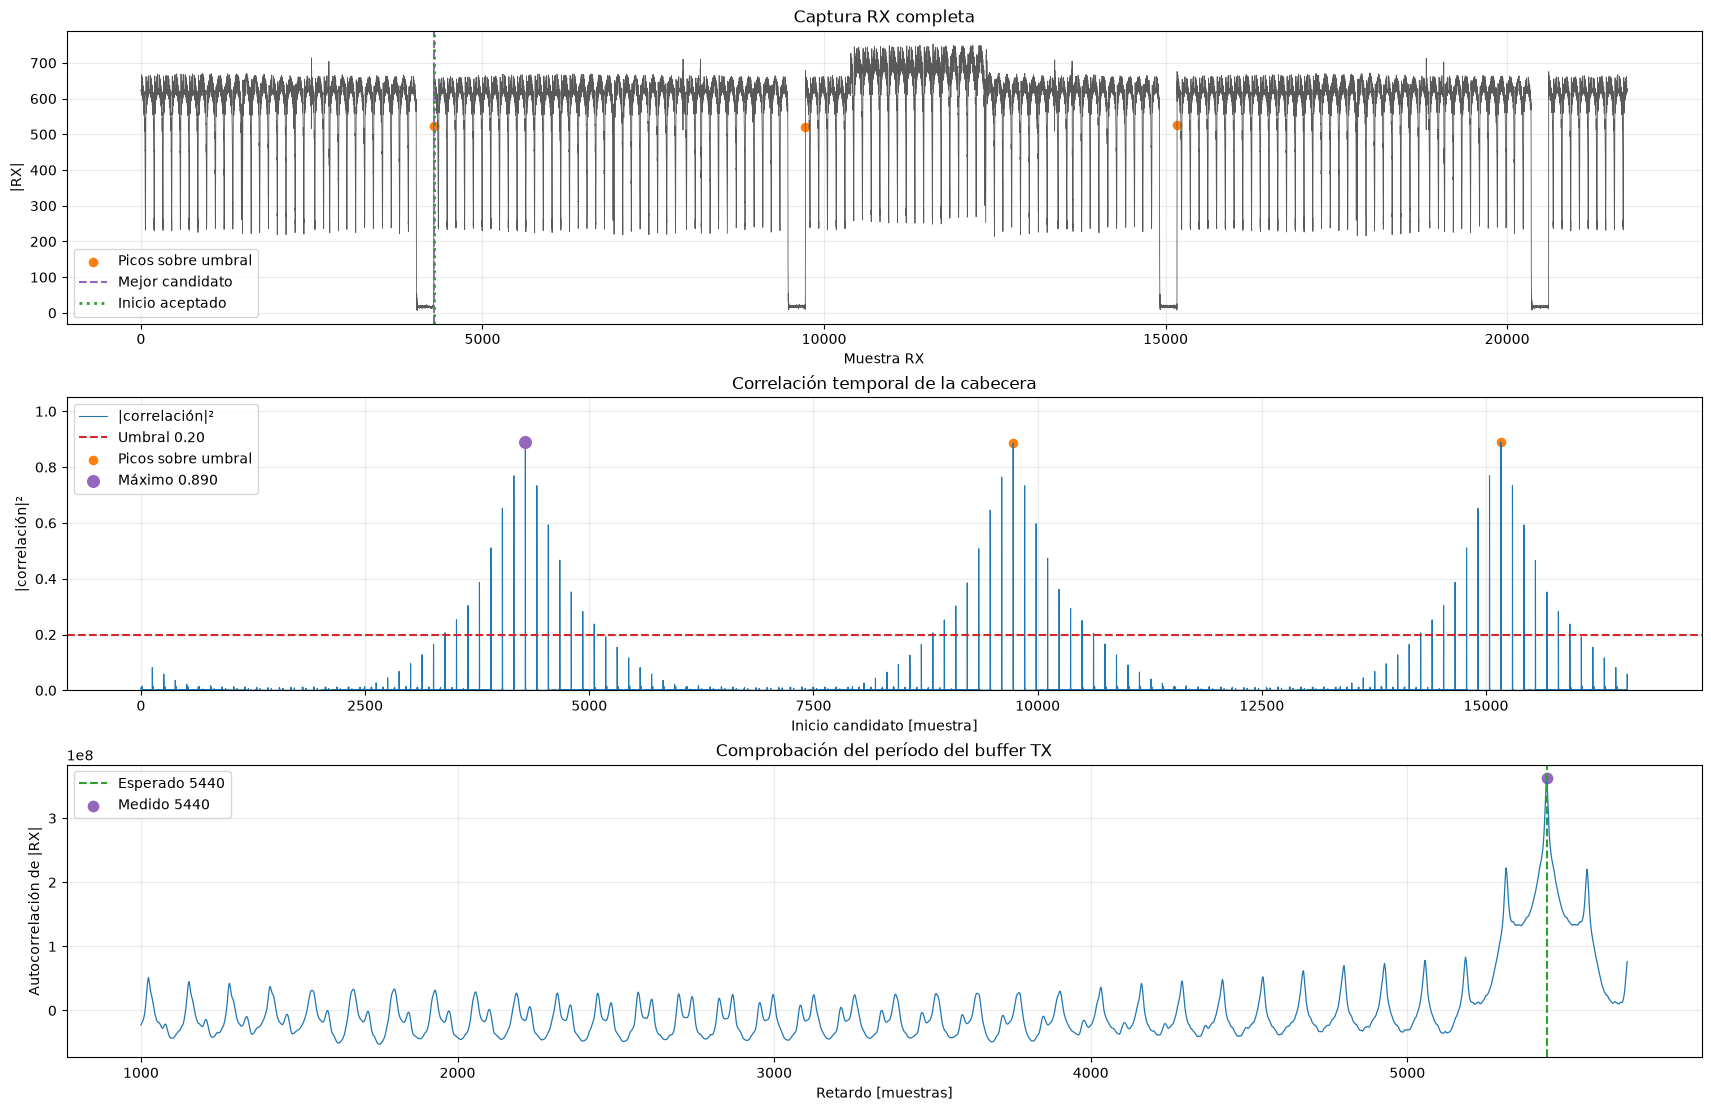

Picos sobre umbral: [4287, 9727, 15167]


In [21]:
picos, _ = find_peaks(puntajes, height=UMBRAL, distance=len(tx_signal)//2)
fig, ax = plt.subplots(3, 1, figsize=(17, 11), constrained_layout=True)
x = np.arange(len(rx_signal))
ax[0].plot(x, envolvente, color='0.35', lw=0.6)
ax[0].scatter(picos, envolvente[picos], color='tab:orange', s=35,
              label='Picos sobre umbral')
ax[0].axvline(candidato, color='tab:purple', ls='--', label='Mejor candidato')
if inicio is not None:
    ax[0].axvline(inicio, color='tab:green', ls=':', lw=2,
                  label='Inicio aceptado')
ax[0].set(title='Captura RX completa', xlabel='Muestra RX', ylabel='|RX|')
ax[0].legend()

ax[1].plot(puntajes, color='tab:blue', lw=0.8, label='|correlación|²')
ax[1].axhline(UMBRAL, color='tab:red', ls='--', label=f'Umbral {UMBRAL:.2f}')
ax[1].scatter(picos, puntajes[picos], color='tab:orange', s=35,
              label='Picos sobre umbral')
ax[1].scatter(candidato, puntajes[candidato], color='tab:purple', s=70,
              zorder=3, label=f'Máximo {puntajes[candidato]:.3f}')
ax[1].set(xlabel='Inicio candidato [muestra]', ylabel='|correlación|²',
          title='Correlación temporal de la cabecera', ylim=(0, 1.05))
ax[1].legend()

lags = np.arange(1000, min(len(tx_signal)+N, len(autocorr)))
ax[2].plot(lags, autocorr[lags], color='tab:blue', lw=0.9)
ax[2].axvline(len(tx_signal), color='tab:green', ls='--',
              label=f'Esperado {len(tx_signal)}')
ax[2].scatter(periodo_rx, autocorr[periodo_rx], color='tab:purple', s=55,
              label=f'Medido {periodo_rx}')
ax[2].set(xlabel='Retardo [muestras]', ylabel='Autocorrelación de |RX|',
          title='Comprobación del período del buffer TX')
ax[2].legend()
for panel in ax:
    panel.grid(alpha=0.25)
plt.show()
print('Picos sobre umbral:', picos.tolist())

**Figura 2:** zoom alrededor del mejor candidato, con las posiciones esperadas de upchirps, downchirps y payload. Debajo se ven I/Q y la similitud de cada parte de la cabecera con su plantilla. Estas barras son **diagnóstico**: la decisión del inicio sigue usando únicamente la curva de correlación completa de la Figura 1.

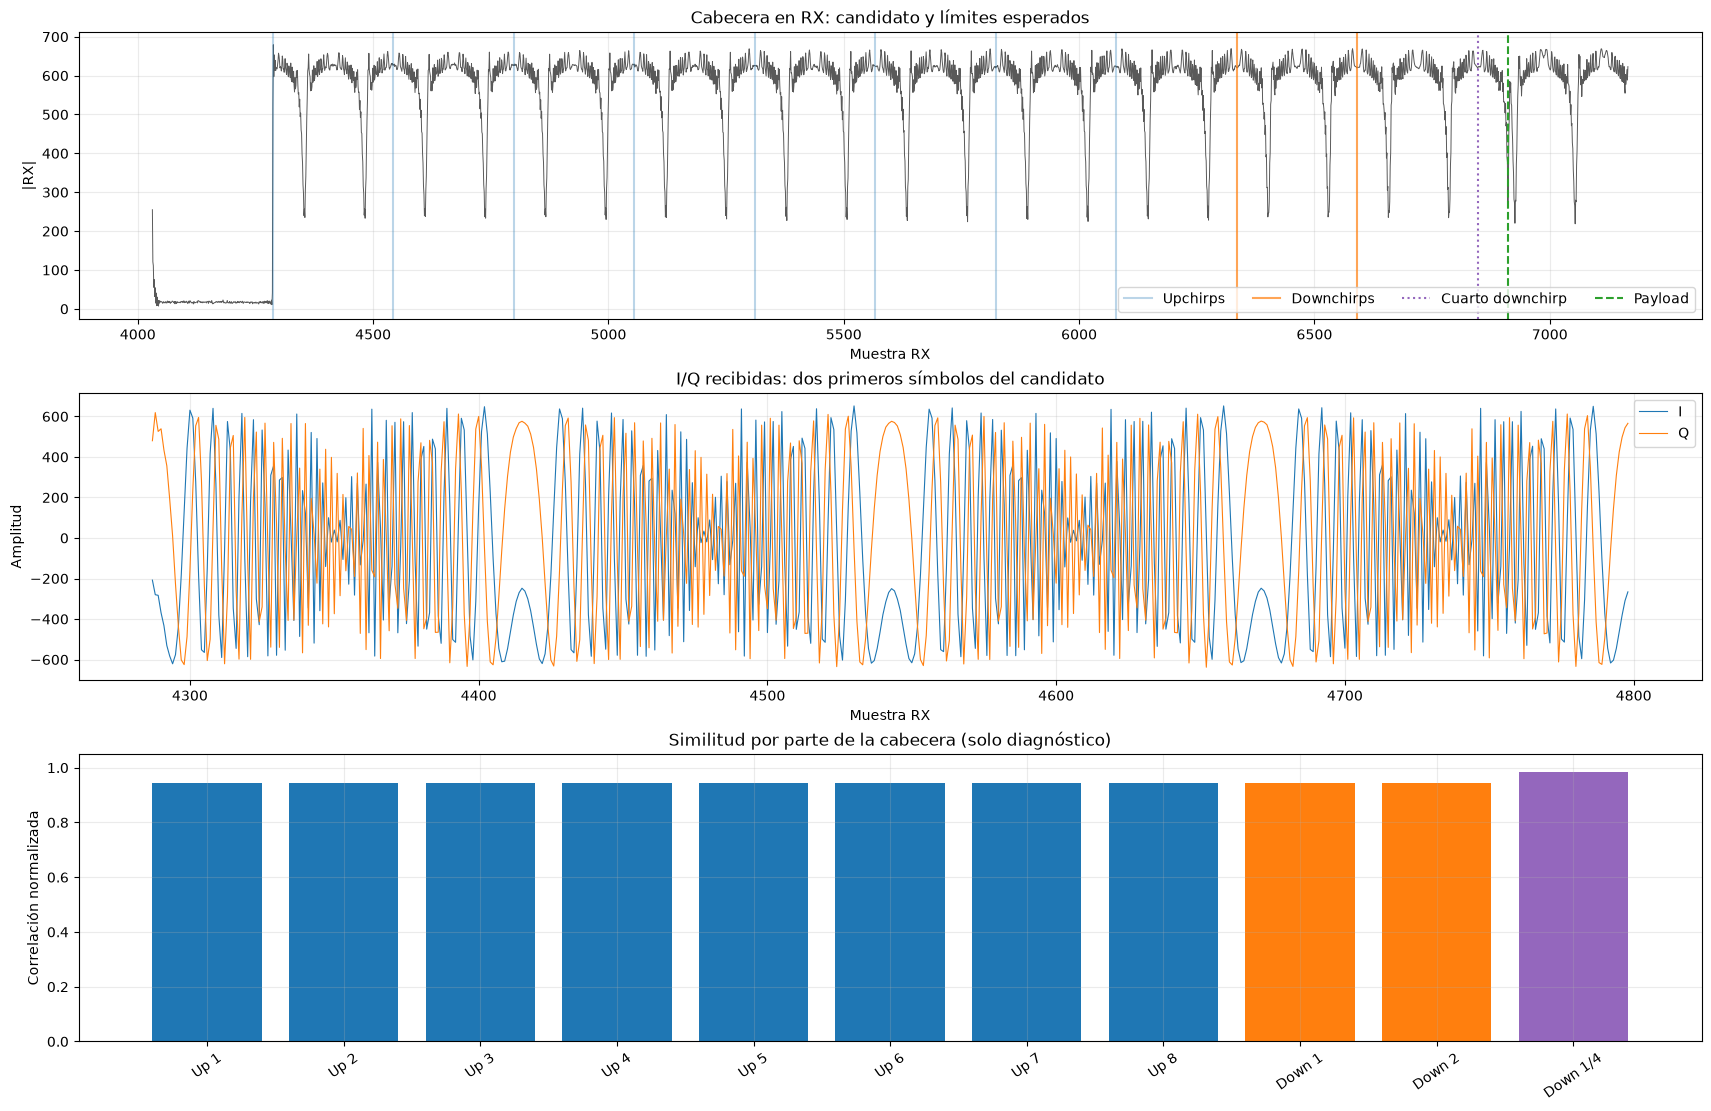

In [22]:
a = max(0, candidato - N)
b = min(len(rx_signal), candidato + len(cabecera) + N)
fig, ax = plt.subplots(3, 1, figsize=(17, 11), constrained_layout=True)
ax[0].plot(np.arange(a, b), envolvente[a:b], color='0.35', lw=0.7)
for j in range(8):
    ax[0].axvline(candidato+j*N, color='tab:blue', alpha=0.3,
                  label='Upchirps' if j == 0 else None)
for j in range(2):
    ax[0].axvline(candidato+(8+j)*N, color='tab:orange', alpha=0.7,
                  label='Downchirps' if j == 0 else None)
ax[0].axvline(candidato+10*N, color='tab:purple', ls=':',
              label='Cuarto downchirp')
ax[0].axvline(candidato+len(cabecera), color='tab:green', ls='--',
              label='Payload')
ax[0].set(title='Cabecera en RX: candidato y límites esperados',
          xlabel='Muestra RX', ylabel='|RX|')
ax[0].legend(ncol=4)

vista = min(2*N, len(rx_signal)-candidato)
muestras = np.arange(candidato, candidato+vista)
ax[1].plot(muestras, rx_signal[candidato:candidato+vista].real,
           lw=0.8, label='I')
ax[1].plot(muestras, rx_signal[candidato:candidato+vista].imag,
           lw=0.8, label='Q')
ax[1].set(title='I/Q recibidas: dos primeros símbolos del candidato',
          xlabel='Muestra RX', ylabel='Amplitud')
ax[1].legend()

segmentos = [(f'Up {j+1}', j*N, (j+1)*N) for j in range(8)]
segmentos += [('Down 1', 8*N, 9*N), ('Down 2', 9*N, 10*N),
             ('Down 1/4', 10*N, len(cabecera))]
calidad = []
for _, desde, hasta in segmentos:
    ref = cabecera[desde:hasta]
    recibido = rx_signal[candidato+desde:candidato+hasta]
    denominador = np.linalg.norm(ref) * np.linalg.norm(recibido)
    calidad.append(float(np.abs(np.vdot(ref, recibido)) / denominador)
                   if denominador else 0.0)
ax[2].bar(np.arange(len(segmentos)), calidad, color=['tab:blue']*8 +
          ['tab:orange']*2 + ['tab:purple'])
ax[2].set_xticks(np.arange(len(segmentos)),
                 [nombre for nombre, _, _ in segmentos], rotation=35)
ax[2].set(title='Similitud por parte de la cabecera (solo diagnóstico)',
          ylabel='Correlación normalizada', ylim=(0, 1.05))
for panel in ax:
    panel.grid(alpha=0.25)
plt.show()

**Figura 3:** si el inicio fue aceptado, cada fila representa un byte del payload recibido después de corregir el desvío de frecuencia. El punto rojo marca el bin elegido por la FFT; el círculo blanco marca el byte enviado. Cuando coinciden, los marcadores se superponen.

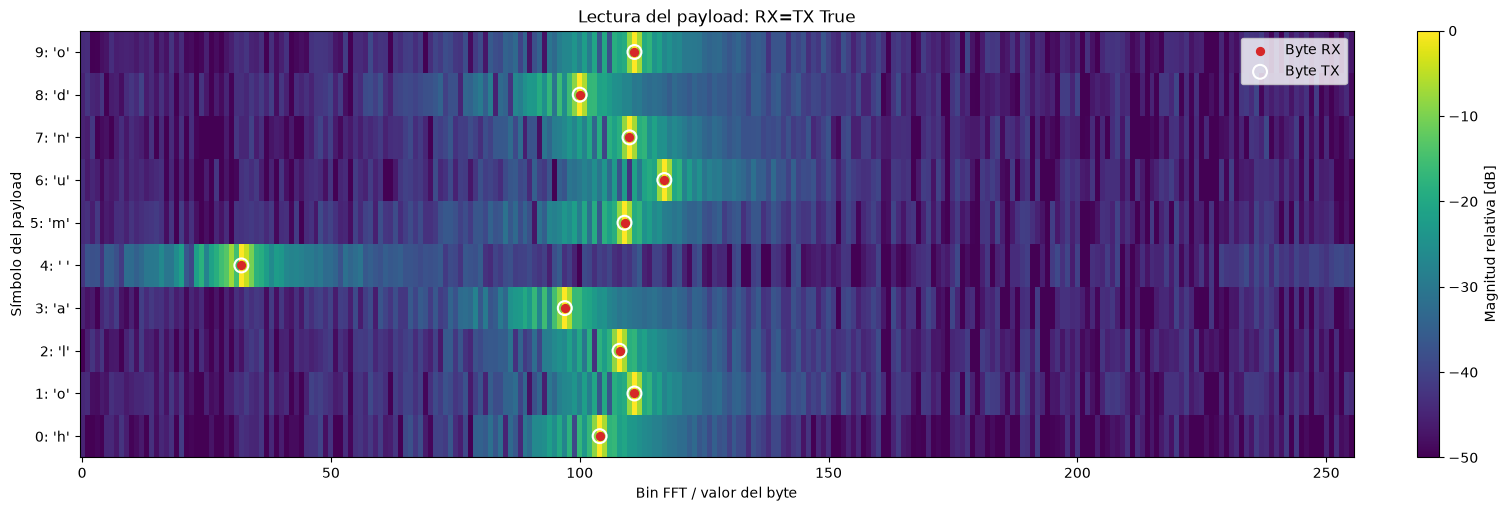

In [18]:
if espectros_rx is None:
    print('No hay espectro de bytes: primero debe confirmarse una trama completa.')
else:
    espectros_db = 20*np.log10(
        espectros_rx / np.maximum(espectros_rx.max(axis=1, keepdims=True), 1e-12)
        + 1e-12)
    fig, ax = plt.subplots(figsize=(15, 5), constrained_layout=True)
    im = ax.imshow(espectros_db, aspect='auto', origin='lower',
                   extent=(-0.5, N-0.5, -0.5, len(mensaje)-0.5),
                   vmin=-50, vmax=0, cmap='viridis')
    filas = np.arange(len(mensaje))
    ax.scatter(np.frombuffer(bytes_rx, dtype=np.uint8), filas,
               color='tab:red', s=32, label='Byte RX')
    ax.scatter(np.frombuffer(mensaje, dtype=np.uint8), filas,
               facecolors='none', edgecolors='white', s=100,
               linewidths=1.5, label='Byte TX')
    ax.set_yticks(filas, [f'{i}: {chr(b)!r}' for i, b in enumerate(mensaje)])
    ax.set(xlabel='Bin FFT / valor del byte', ylabel='Símbolo del payload',
           title=f'Lectura del payload: RX=TX {bytes_rx == mensaje}')
    ax.legend()
    fig.colorbar(im, ax=ax, label='Magnitud relativa [dB]')
    plt.show()

**Lectura final:** período 5440 → se repite la trama completa; pico de correlación sobre 0,20 → inicio aceptado; bytes RX iguales a `hola mundo` → transmisión y lectura correctas. Si el período no coincide, revisar el envío antes de ajustar el umbral.